# 3D Row-Input Surrogate in Explicit Coupled Runs

Results of `create_predictor_3d_rows.py --apply --explicit-dt ...`: the reduced bottom half integrates explicitly with (possibly varying) steps $\Delta t_n$, and the surrogate runs subcycled on its own grid $T_k = k \cdot 5\times10^{-7}$ s, with the interface interpolated linearly between its predictions.

- **Input ($X$):** displacements at 2.5, 5, 7.5, 10 mm below each of the 151 interface nodes (held between surrogate calls)
- **Predicted output ($Y$):** interface displacements $u_x, u_y, u_z$ (prescribed on the reduced domain)
- **Internal state ($Z$):** PCA-reduced equivalent plastic strain of the removed top half

Every array has one row per **explicit** step, so everything is plotted against **time**, not the step index. The reference is the explicit full model run in lockstep with the same step sequence.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "savefig.dpi": 300,
    "figure.autolayout": False,
})

colors_ordered = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown", "tab:pink", "tab:cyan", "tab:olive"]
run_colors = ["black", "tab:red", "tab:blue", "tab:green", "tab:purple"]


## 1. Configuration & Loading

In [9]:
law = "plastic"
freq = 1000
run_tag = "explicit_jitter_full2000"   # also: "explicit_full2000" (constant dt)

# (version, data tag of the training set, label). The data tag selects the PCA basis of the internal state.
runs = [
    ("09", "", "v09 (implicit training data)"),
    ("e01", "explicit", "e01 (explicit training data)"),
]
main_run = 1          # run shown in the detailed overview figure
save_figures = False

results_dir = Path("results_3d_inv")
if not results_dir.exists() and Path("workspace/results_3d_inv").exists():
    results_dir = Path("workspace/results_3d_inv")
data_dir = Path("training_data_3d_inv")
if not data_dir.exists() and Path("workspace/training_data_3d_inv").exists():
    data_dir = Path("workspace/training_data_3d_inv")

suffix_tct = f"3d_{law}_rows_f{freq}_{run_tag}"
times = np.load(results_dir / f"times_3d_{law}_f{freq}_{run_tag}.npy")      # end time of each explicit step [s]
t_ms = times * 1e3
dt = np.diff(np.concatenate([[0.0], times]))
ref_out = np.load(results_dir / f"tct_results_out_{suffix_tct}.npy")       # reference interface displacement
n_iface = ref_out.shape[1]
n_nodes = n_iface // 3

def load_run(version, data_tag):
    suffix_sm = f"3d_{law}_spils_net_gnn_rows_v{version}_f{freq}_{run_tag}"
    r = {
        "out": np.load(results_dir / f"sm_results_out_{suffix_sm}.npy")[:, :n_iface],
        "internal": np.load(results_dir / f"sm_results_internal_{suffix_sm}.npy"),
        "in": np.load(results_dir / f"sm_results_in_{suffix_sm}.npy"),
        "error": np.load(results_dir / f"sm_results_error_{suffix_sm}.npy"),
    }
    basis = f"_{data_tag}" if data_tag else ""
    ref_int = results_dir / f"tct_results_internal_{suffix_tct}{basis}.npy"
    r["ref_internal"] = np.load(ref_int) if ref_int.exists() else None
    if r["ref_internal"] is None:
        print(f"v{version}: no reference internal state ({ref_int.name}); rerun the apply to create it")
    return r

results = [load_run(v, tag) for v, tag, _ in runs]
print(f"{len(times)} explicit steps, dt in [{dt.min():.3g}, {dt.max():.3g}] s, end time {times[-1]*1e3:.3f} ms, {n_nodes} interface nodes")
for (v, _, label), r in zip(runs, results):
    assert len(r["out"]) == len(times), f"{label}: {len(r['out'])} steps vs {len(times)} reference steps (different run tag?)"


10663 explicit steps, dt in [6.25e-08, 1.25e-07] s, end time 1.000 ms, 151 interface nodes


## 2. Overview of One Run (Reference vs Surrogate)

Solid, semi-transparent: explicit full-model reference. Dashed: coupled run with the surrogate. Panel (a) shows the surrogate's input row at 2.5 mm depth ($u_z$), held between surrogate calls.

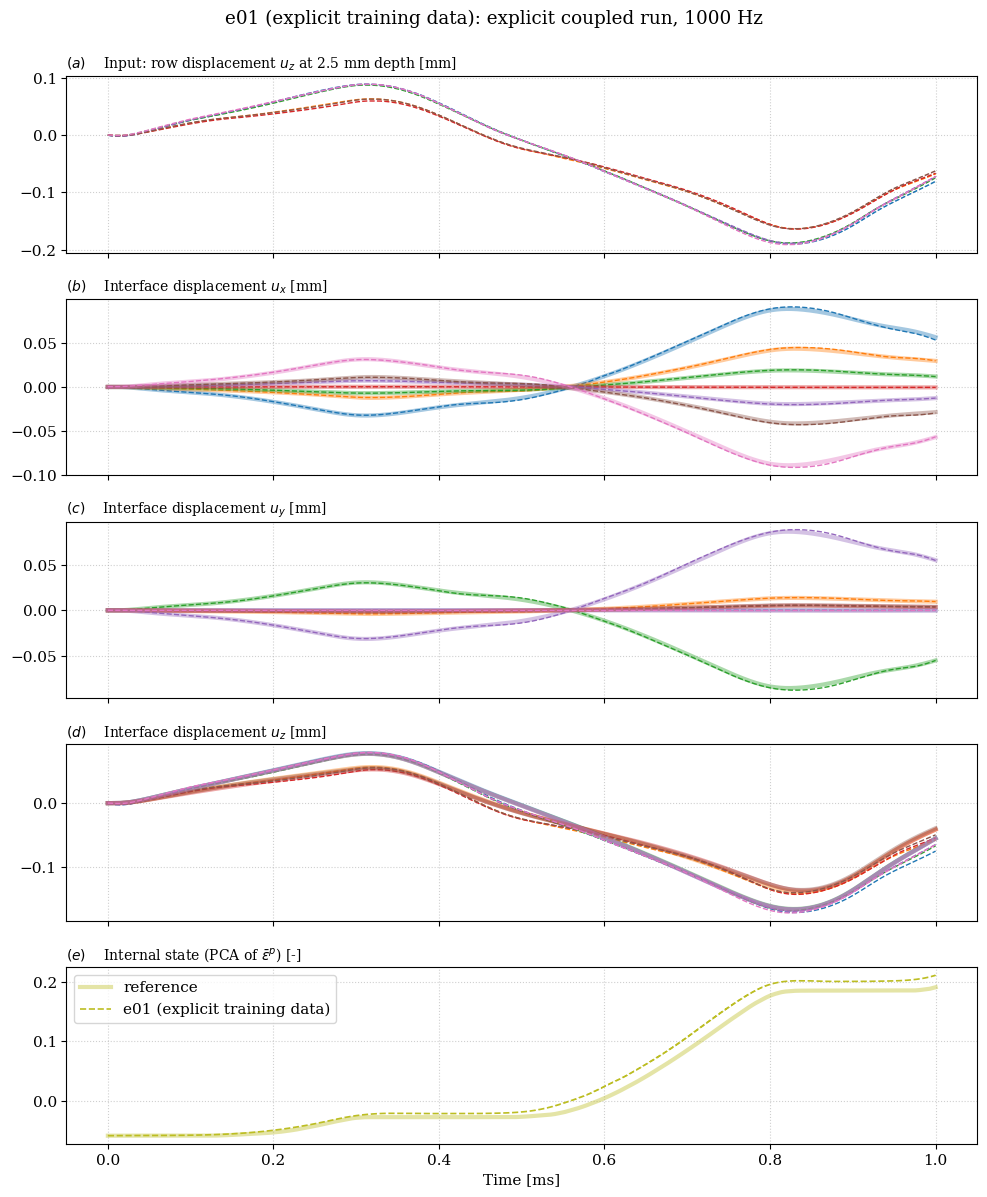

In [10]:
sample_nodes = [0, 25, 50, 75, 100, 125, 150]
version, _, label = runs[main_run]
r = results[main_run]
n_depth_features = r["in"].shape[1] // n_nodes   # 3 per input depth

fig, axs = plt.subplots(5, 1, figsize=(10, 12), sharex=True)
axs[0].set_title(r"$(a)\quad$ Input: row displacement $u_z$ at 2.5 mm depth [mm]", fontsize=10, loc="left")
for i, c in enumerate(["x", "y", "z"]):
    axs[i + 1].set_title(rf"$({'bcd'[i]})\quad$ Interface displacement $u_{c}$ [mm]", fontsize=10, loc="left")
axs[4].set_title(r"$(e)\quad$ Internal state (PCA of $\bar{\varepsilon}^p$) [-]", fontsize=10, loc="left")

for k, node in enumerate(sample_nodes):
    color = colors_ordered[k % len(colors_ordered)]
    axs[0].plot(t_ms, r["in"][:, node * n_depth_features + 2], "--", color=color, linewidth=1)
    for c in range(3):
        axs[c + 1].plot(t_ms, ref_out[:, node * 3 + c], color=color, linewidth=3, alpha=0.4)
        axs[c + 1].plot(t_ms, r["out"][:, node * 3 + c], "--", color=color, linewidth=1)
if r["ref_internal"] is not None:
    axs[4].plot(t_ms, r["ref_internal"], color="tab:olive", linewidth=3, alpha=0.4, label="reference")
axs[4].plot(t_ms, r["internal"], "--", color="tab:olive", linewidth=1.2, label=label)
axs[4].legend(loc="upper left")
axs[4].set_xlabel("Time [ms]")
for ax in axs:
    ax.grid(True, linestyle=":", alpha=0.6)
fig.suptitle(f"{label}: explicit coupled run, {freq} Hz", y=0.995)
fig.tight_layout()
if save_figures:
    plt.savefig(f"figures/3d_{law}_explicit_overview_v{version}_{freq}.pdf", bbox_inches="tight", pad_inches=0.05)
plt.show()


## 3. Run Comparison: Error Measures over Time

- **Rigid z-shift:** mean over the interface of $u_z^{SM} - u_z^{ref}$, the slow offset that builds up in coupled runs.
- **Interface error:** $\|u^{SM}_\Gamma - u^{ref}_\Gamma\| / \max_t \|u^{ref}_\Gamma\|$ per step.
- **Domain error:** relative error of the whole reduced domain per step, as saved by the apply.

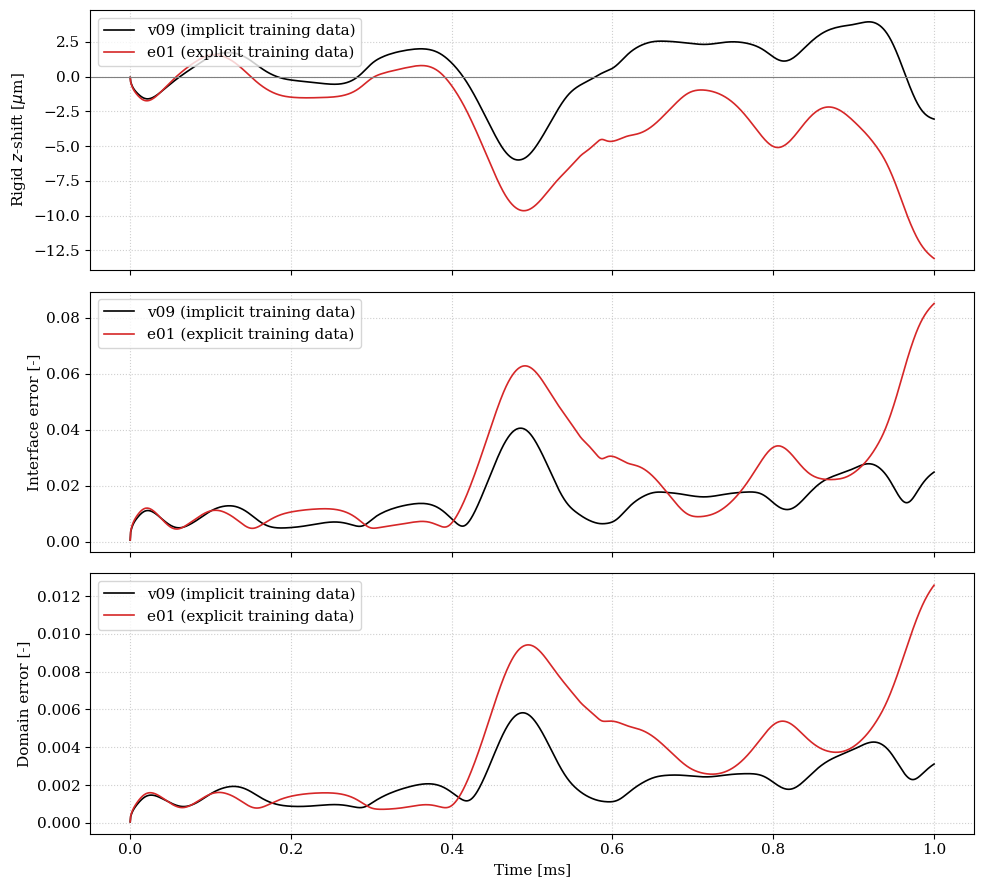

In [11]:
ref_norm = np.linalg.norm(ref_out, axis=1).max()
fig, axs = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for k, ((version, _, label), r) in enumerate(zip(runs, results)):
    d = r["out"] - ref_out
    z_shift = d.reshape(len(d), n_nodes, 3)[:, :, 2].mean(axis=1) * 1e3
    axs[0].plot(t_ms, z_shift, color=run_colors[k], label=label, linewidth=1.2)
    axs[1].plot(t_ms, np.linalg.norm(d, axis=1) / ref_norm, color=run_colors[k], label=label, linewidth=1.2)
    axs[2].plot(t_ms, r["error"], color=run_colors[k], label=label, linewidth=1.2)
axs[0].axhline(0, color="gray", linewidth=0.8)
axs[0].set_ylabel(r"Rigid $z$-shift [$\mu$m]")
axs[1].set_ylabel("Interface error [-]")
axs[2].set_ylabel("Domain error [-]")
axs[2].set_xlabel("Time [ms]")
for ax in axs:
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper left")
fig.tight_layout()
if save_figures:
    plt.savefig(f"figures/3d_{law}_explicit_errors_{freq}.pdf", bbox_inches="tight", pad_inches=0.05)
plt.show()


## 4. Internal State Progression

Each model's internal state against the reference reduced with **that model's** PCA basis (the implicit and explicit datasets have slightly different bases, so values only compare across runs approximately).

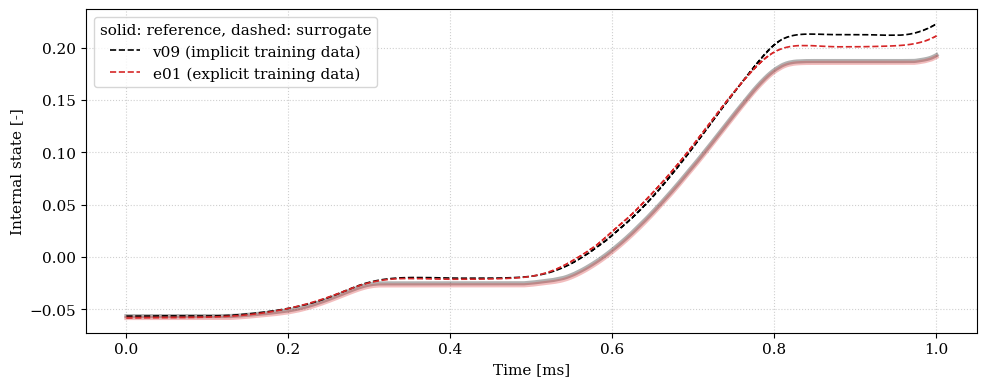

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
for k, ((version, _, label), r) in enumerate(zip(runs, results)):
    if r["ref_internal"] is not None:
        ax.plot(t_ms, r["ref_internal"], color=run_colors[k], linewidth=3, alpha=0.3)
    ax.plot(t_ms, r["internal"], "--", color=run_colors[k], linewidth=1.2, label=label)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Internal state [-]")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", title="solid: reference, dashed: surrogate")
fig.tight_layout()
plt.show()


## 5. Explicit Step Sizes

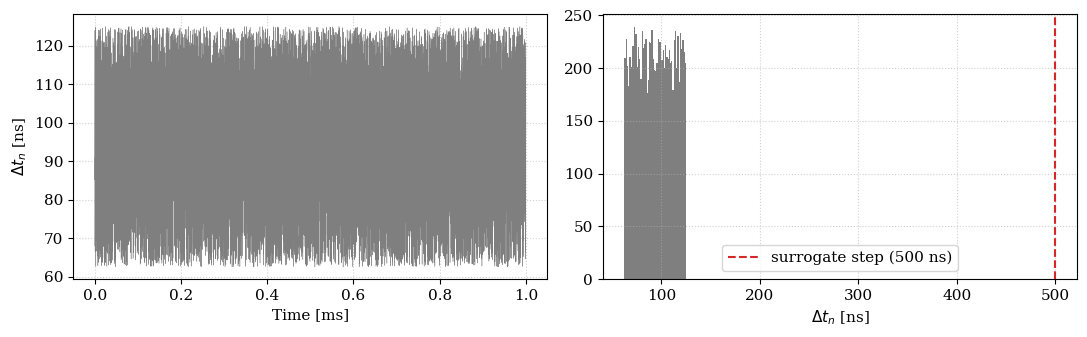

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(t_ms, dt * 1e9, linewidth=0.3, color="tab:gray")
axs[0].set_xlabel("Time [ms]")
axs[0].set_ylabel(r"$\Delta t_n$ [ns]")
axs[1].hist(dt * 1e9, bins=50, color="tab:gray")
axs[1].axvline(500, color="tab:red", linestyle="--", label="surrogate step (500 ns)")
axs[1].set_xlabel(r"$\Delta t_n$ [ns]")
axs[1].legend()
for ax in axs:
    ax.grid(True, linestyle=":", alpha=0.6)
fig.tight_layout()
plt.show()


## 6. Summary

In [14]:
print(f"{'run':32s} {'domain err*':>11s} {'iface err':>10s} {'max |z-shift|':>14s} {'final internal (SM / ref)':>26s}")
for (version, _, label), r in zip(runs, results):
    d = r["out"] - ref_out
    iface = np.linalg.norm(d) / np.linalg.norm(ref_out)
    z_max = np.abs(d.reshape(len(d), n_nodes, 3)[:, :, 2].mean(axis=1)).max() * 1e3
    ref_final = f"{r['ref_internal'][-1]:.4f}" if r["ref_internal"] is not None else "n/a"
    print(f"{label:32s} {np.sqrt(np.mean(r['error']**2)) * 100:10.2f}% {iface * 100:9.2f}% {z_max:11.1f} um {r['internal'][-1]:12.4f} / {ref_final}")
print("* rms over the steps of the per-step domain error (normalised by the largest reference norm); the apply log reports a slightly different global measure")


run                              domain err*  iface err  max |z-shift|  final internal (SM / ref)
v09 (implicit training data)           0.25%      3.38%         6.0 um       0.2228 / 0.1929
e01 (explicit training data)           0.47%      5.98%        13.1 um       0.2114 / 0.1911
* rms over the steps of the per-step domain error (normalised by the largest reference norm); the apply log reports a slightly different global measure
